# **Part 1: Data Preprocessing and Merging**

In [1]:
# Install necessary libraries
!pip install shap xgboost scikit-learn pandas matplotlib seaborn --quiet

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load data files
path = "/content/"

account = pd.read_csv(path + 'account.csv', sep=';')
client = pd.read_csv(path + 'client.csv', sep=';')
card = pd.read_csv(path + 'card.csv', sep=';')
disp = pd.read_csv(path + 'disp.csv', sep=';')
loan = pd.read_csv(path + 'loan.csv', sep=';')
order = pd.read_csv(path + 'order.csv', sep=';')
trans = pd.read_csv(path + 'trans.csv', sep=';', engine='python', on_bad_lines='skip')
district = pd.read_csv(path + 'district.csv', sep=';')

In [3]:
# Merge core tables: client + disp + account + trans
disp_client = disp.merge(client, on='client_id')
disp_account = disp_client.merge(account, on='account_id')
data = disp_account.merge(trans, on='account_id')
print(data.head())


   disp_id  client_id  account_id type_x  birth_number  district_id_x  \
0        1          1           1  OWNER        706213             18   
1        1          1           1  OWNER        706213             18   
2        1          1           1  OWNER        706213             18   
3        1          1           1  OWNER        706213             18   
4        1          1           1  OWNER        706213             18   

   district_id_y         frequency  date_x  trans_id  date_y  type_y  \
0             18  POPLATEK MESICNE  950324         1  950324  PRIJEM   
1             18  POPLATEK MESICNE  950324         5  950413  PRIJEM   
2             18  POPLATEK MESICNE  950324       199  950423  PRIJEM   
3             18  POPLATEK MESICNE  950324   3530438  950430  PRIJEM   
4             18  POPLATEK MESICNE  950324         6  950513  PRIJEM   

       operation   amount  balance k_symbol bank     account  
0          VKLAD   1000.0   1000.0      NaN  NaN         NaN  
1 

In [4]:
data.shape

(1262625, 18)

In [5]:
data.describe()

,disp_id,client_id,account_id,birth_number,district_id_x,district_id_y,date_x,trans_id,date_y,amount,balance,account
count,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,1.262625e+06,3.615920e+05
mean,3.528402e+03,3.556496e+03,2.927288e+03,5.419768e+05,3.746681e+01,3.744931e+01,9.445292e+05,1.332701e+06,9.656211e+05,5.873195e+03,3.842065e+04,4.598302e+07
std,2.973958e+03,3.045982e+03,2.478426e+03,1.685886e+05,2.513161e+01,2.533084e+01,1.415380e+04,1.228685e+06,1.398746e+04,9.470080e+03,2.210205e+04,3.059498e+07
min,1.000000e+00,1.000000e+00,1.000000e+00,1.108200e+05,1.000000e+00,1.000000e+00,9.301010e+05,1.000000e+00,9.301010e+05,0.000000e+00,-4.112570e+04,0.000000e+00
25%,1.450000e+03,1.450000e+03,1.201000e+03,4.201120e+05,1.400000e+01,1.300000e+01,9.307250e+05,4.263580e+05,9.601130e+05,1.349000e+02,2.225640e+04,1.822216e+07
50%,2.933000e+03,2.933000e+03,2.428000e+03,5.503130e+05,3.900000e+01,3.800000e+01,9.407100e+05,8.550880e+05,9.704090e+05,2.100000e+03,3.296050e+04,4.604561e+07
75%,4.398000e+03,4.398000e+03,3.647000e+03,6.852160e+05,6.000000e+01,6.100000e+01,9.603080e+05,2.106623e+06,9.802280e+05,6.694000e+03,4.943620e+04,7.232217e+07
max,1.369000e+04,1.399800e+04,1.138200e+04,8.759270e+05,7.700000e+01,7.700000e+01,9.712290e+05,3.682987e+06,9.812310e+05,8.740000e+04,2.096370e+05,9.999420e+07


In [6]:
display(data.head())

,disp_id,client_id,account_id,type_x,birth_number,district_id_x,district_id_y,frequency,date_x,trans_id,date_y,type_y,operation,amount,balance,k_symbol,bank,account
0,1,1,1,OWNER,706213,18,18,POPLATEK MESICNE,950324,1,950324,PRIJEM,VKLAD,1000.0,1000.0,NaN,NaN,NaN
1,1,1,1,OWNER,706213,18,18,POPLATEK MESICNE,950324,5,950413,PRIJEM,PREVOD Z UCTU,3679.0,4679.0,NaN,AB,41403269.0
2,1,1,1,OWNER,706213,18,18,POPLATEK MESICNE,950324,199,950423,PRIJEM,VKLAD,12600.0,17279.0,NaN,NaN,NaN
3,1,1,1,OWNER,706213,18,18,POPLATEK MESICNE,950324,3530438,950430,PRIJEM,NaN,19.2,17298.2,UROK,NaN,NaN
4,1,1,1,OWNER,706213,18,18,POPLATEK MESICNE,950324,6,950513,PRIJEM,PREVOD Z UCTU,3679.0,20977.2,NaN,AB,41403269.0


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1262625 entries, 0 to 1262624
Data columns (total 18 columns):
 #   Column         Non-Null Count    Dtype  
---  ------         --------------    -----  
 0   disp_id        1262625 non-null  int64  
 1   client_id      1262625 non-null  int64  
 2   account_id     1262625 non-null  int64  
 3   type_x         1262625 non-null  object 
 4   birth_number   1262625 non-null  int64  
 5   district_id_x  1262625 non-null  int64  
 6   district_id_y  1262625 non-null  int64  
 7   frequency      1262625 non-null  object 
 8   date_x         1262625 non-null  int64  
 9   trans_id       1262625 non-null  int64  
 10  date_y         1262625 non-null  int64  
 11  type_y         1262625 non-null  object 
 12  operation      1044314 non-null  object 
 13  amount         1262625 non-null  float64
 14  balance        1262625 non-null  float64
 15  k_symbol       692808 non-null   object 
 16  bank           336049 non-null   object 
 17  account 

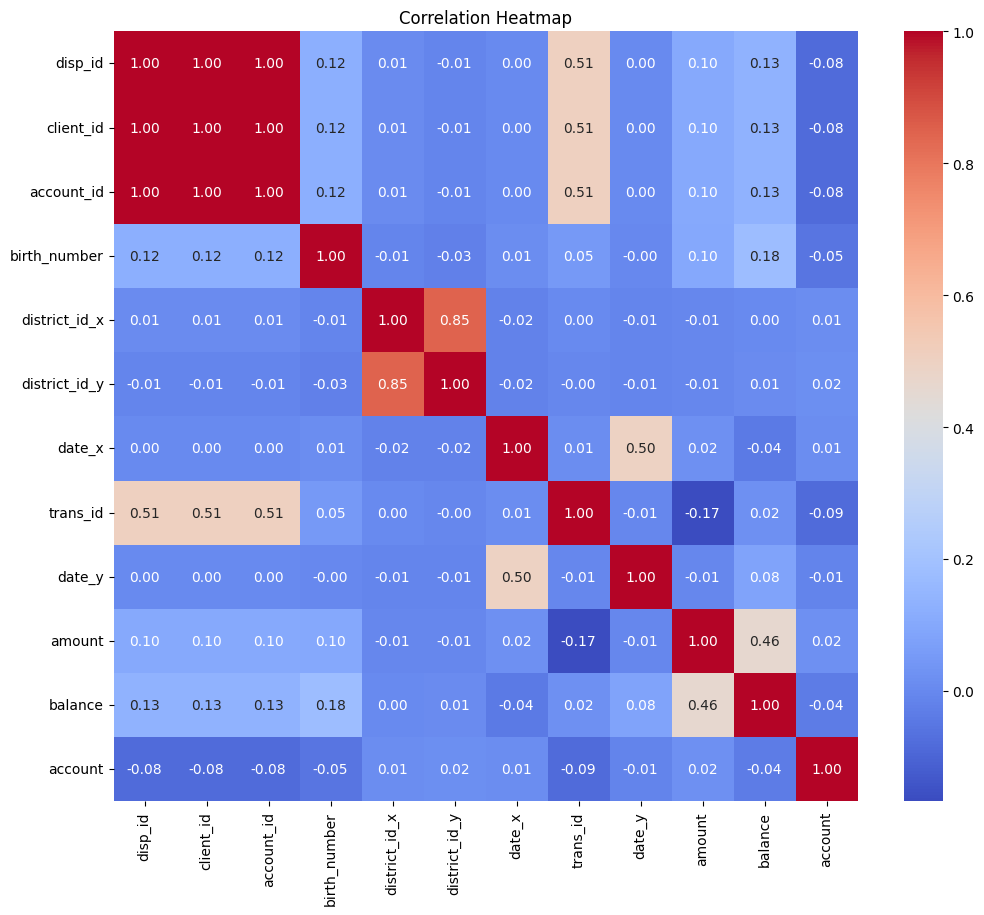

In [8]:
!pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix with numeric_only=True
correlation_matrix = data.corr(numeric_only=True)

# Create the heatmap using seaborn
plt.figure(figsize=(12, 10))  # Adjust figure size if needed
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

# **Part 2: Behavioral Embedding with Autoencoder**









##Step 1: Aggregate Transaction Features per Account

In [9]:
# Convert date to month if available
trans['date'] = pd.to_datetime(trans['date'], errors='coerce')

# Create transaction direction feature
trans['amount_signed'] = trans.apply(lambda x: -x['amount'] if x['type'] == 'debit' else x['amount'], axis=1)

# Aggregate behavior per account (monthly stats)
monthly_stats = (
    trans.groupby(['account_id', trans['date'].dt.to_period('M')])
    .agg({
        'amount_signed': ['sum', 'mean', 'count', 'max', 'min'],
        'balance': ['mean']
    })
    .reset_index()
)
monthly_stats.columns = ['account_id', 'month', 'amt_sum', 'amt_mean', 'amt_count', 'amt_max', 'amt_min', 'bal_mean']
monthly_stats = monthly_stats.fillna(0)


##Step 2: Pivot to Time-Series Per Account

In [10]:
# Create time-series format: one row per account, each column a monthly stat
pivot = monthly_stats.pivot_table(index='account_id', columns='month', values='amt_sum', fill_value=0)

# Normalize the vectors
scaler = MinMaxScaler()
X = scaler.fit_transform(pivot)

print(f"Embedding input shape: {X.shape}")  # Expected: (n_accounts, n_months)


Embedding input shape: (4500, 1)


##Step 3: Train Autoencoder

In [11]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# Define encoder-decoder architecture
input_dim = X.shape[1]
encoding_dim = 10  # Embedding size

input_layer = Input(shape=(input_dim,))
encoded = Dense(64, activation='relu')(input_layer)
encoded = Dense(encoding_dim, activation='relu')(encoded)
decoded = Dense(64, activation='relu')(encoded)
decoded = Dense(input_dim, activation='sigmoid')(decoded)

autoencoder = Model(input_layer, decoded)
encoder = Model(input_layer, encoded)

autoencoder.compile(optimizer=Adam(0.001), loss='mse')
autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,547 (6.04 KB)

 Trainable params: 1,547 (6.04 KB)

 Non-trainable params: 0 (0.00 B)

##Step 4: Train and Extract Embeddings

In [12]:
# Train autoencoder
autoencoder.fit(X, X, epochs=50, batch_size=32, shuffle=True, validation_split=0.2)

# Extract embeddings
embeddings = encoder.predict(X)
embedding_df = pd.DataFrame(embeddings)
embedding_df['account_id'] = pivot.index.values
print(embedding_df.head())


Epoch 1/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.1007 - val_loss: 0.0393
Epoch 2/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0113 - val_loss: 7.5711e-04
Epoch 3/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.4057e-04 - val_loss: 2.3987e-04
Epoch 4/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.3711e-04 - val_loss: 9.4327e-05
Epoch 5/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.2114e-04 - val_loss: 7.5097e-05
Epoch 6/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.2264e-05 - val_loss: 4.9460e-05
Epoch 7/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6.4147e-05 - val_loss: 5.5999e-05
Epoch 8/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.4294e-05 - val_loss: 4.6884e-05
Epoch 9/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.6482e-05 - val_loss: 4.2249e-05
Epoch 10/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.4948e-05 - val_loss: 5.0544e-05
Epoch 11/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.0222e-0


#**Part 3: Ranking Module Using XGBoost**



##Step 1: Simulate Recommendation Labels

In [13]:
# Merge embeddings with loan and card to simulate a recommendation label
# For demo: assume customers with a loan = 1, others = 0

labels = loan[['account_id']].copy()
labels['target'] = 1  # positive recommendation outcome
all_accounts = embedding_df[['account_id']].copy()
all_accounts = all_accounts.merge(labels, on='account_id', how='left')
all_accounts['target'] = all_accounts['target'].fillna(0)

# Join with embeddings
embedding_features = embedding_df.drop('account_id', axis=1)
X = embedding_features.values
y = all_accounts['target'].values


## Step 2: Train-Test Split and XGBoost Training

In [14]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)

# Evaluation
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print("AUC Score:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))


              precision    recall  f1-score   support

         0.0       0.85      0.99      0.92       764
         1.0       0.40      0.04      0.08       136

    accuracy                           0.85       900
   macro avg       0.63      0.52      0.50       900
weighted avg       0.78      0.85      0.79       900

AUC Score: 0.7195391900215584


In [15]:
pip install imblearn --quiet

In [16]:
## Using SMOTE to adddress class imbalance
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

print(f"Original training set shape: {X_train.shape}, {y_train.shape}")
print(f"Resampled training set shape: {X_resampled.shape}, {y_resampled.shape}")
print(f"Original class distribution: {np.bincount(y_train.astype(int))}")
print(f"Resampled class distribution: {np.bincount(y_resampled.astype(int))}")

Original training set shape: (3600, 10), (3600,)
Resampled training set shape: (6108, 10), (6108,)
Original class distribution: [3054  546]
Resampled class distribution: [3054 3054]


In [17]:
model_resampled = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model_resampled.fit(X_resampled, y_resampled)

print("XGBoost Classifier trained with SMOTE resampled data.")

XGBoost Classifier trained with SMOTE resampled data.


In [18]:
y_pred_resampled = model_resampled.predict(X_test)
print("--- Evaluation on Test Set after SMOTE ---")
print(classification_report(y_test, y_pred_resampled))
print("AUC Score (after SMOTE):", roc_auc_score(y_test, model_resampled.predict_proba(X_test)[:, 1]))

--- Evaluation on Test Set after SMOTE ---
              precision    recall  f1-score   support

         0.0       0.91      0.68      0.77       764
         1.0       0.25      0.62      0.36       136

    accuracy                           0.67       900
   macro avg       0.58      0.65      0.57       900
weighted avg       0.81      0.67      0.71       900

AUC Score (after SMOTE): 0.7179944949183862


##**Hyperparameter Tuning for XGBoost**

In [19]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
# Define the parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.2],
    'objective': ['binary:logistic'],
    'eval_metric': ['logloss']
}
# Initialize an XGBClassifier
xgb_model = XGBClassifier(use_label_encoder=False, random_state=42)

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='recall',
    cv=3,
    verbose=1,
    n_jobs=-1  # Use all available cores
)
# Fit GridSearchCV to the SMOTE-resampled data
grid_search.fit(X_resampled, y_resampled)
# Print the best parameters and best recall score
print("Best parameters found: ", grid_search.best_params_)
print(f"Best recall score found: {grid_search.best_score_:.4f}")
# Store the best estimator
best_xgb_model = grid_search.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits
Best parameters found:  {'colsample_bytree': 1.0, 'eval_metric': 'logloss', 'gamma': 0.2, 'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100, 'objective': 'binary:logistic', 'subsample': 0.8}
Best recall score found: 0.8477


In [20]:
from sklearn.metrics import classification_report, roc_auc_score

# Make predictions on the test set using the best_xgb_model
y_pred_tuned = best_xgb_model.predict(X_test)

# Calculate probability scores for the positive class
y_proba_tuned = best_xgb_model.predict_proba(X_test)[:, 1]

# Print the classification report
print("--- Evaluation on Test Set after Hyperparameter Tuning ---")
print(classification_report(y_test, y_pred_tuned))

# Calculate and print the ROC AUC score
print("AUC Score (after Hyperparameter Tuning):", roc_auc_score(y_test, y_proba_tuned))

--- Evaluation on Test Set after Hyperparameter Tuning ---
              precision    recall  f1-score   support

         0.0       0.94      0.59      0.73       764
         1.0       0.25      0.78      0.38       136

    accuracy                           0.62       900
   macro avg       0.60      0.69      0.56       900
weighted avg       0.83      0.62      0.68       900

AUC Score (after Hyperparameter Tuning): 0.7466700030797659


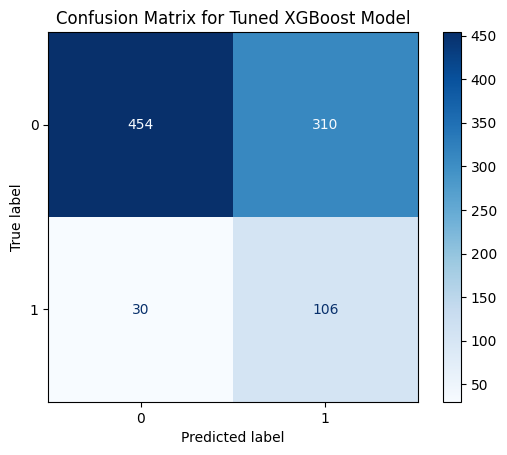

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_tuned, labels=best_xgb_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_xgb_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Tuned XGBoost Model')
plt.show()

#**Part 4: Explainability Module Using SHAP**


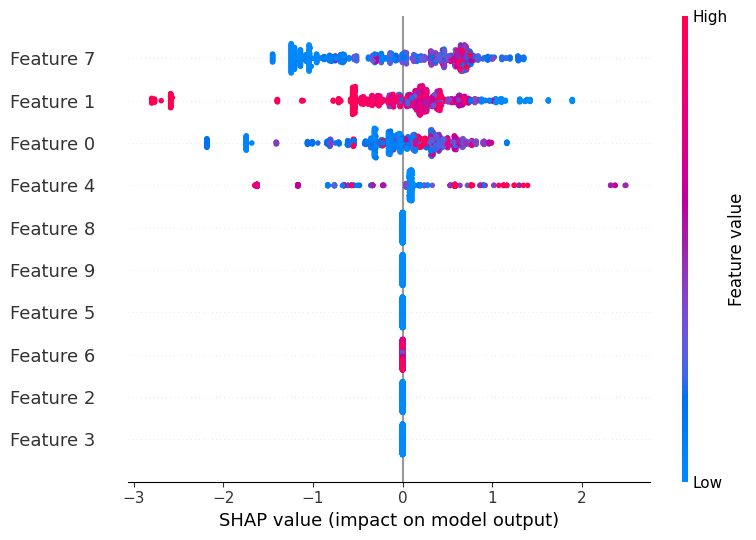

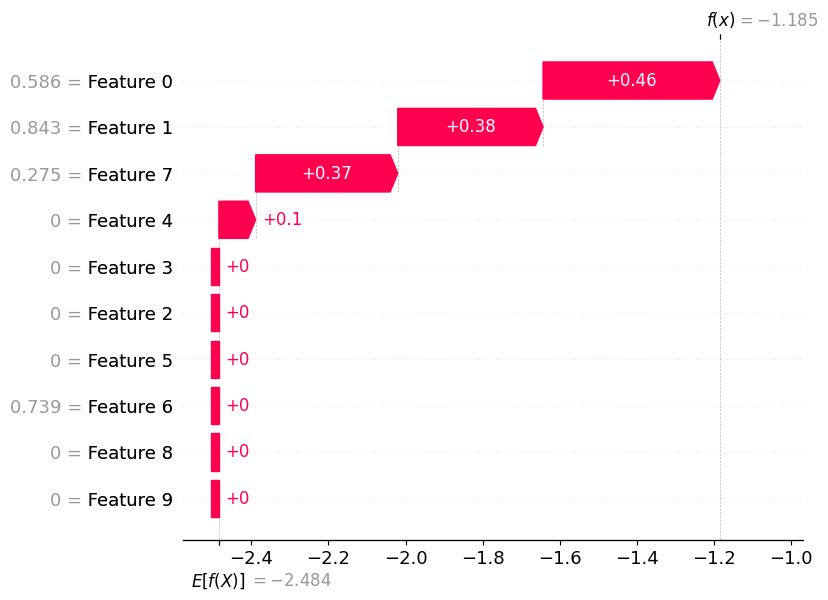

In [22]:
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

# Global summary of feature impact
shap.summary_plot(shap_values, X_test)

# Local explanation for a single customer
index = 0  # index of the test user you want to explain
shap.plots.waterfall(shap_values[index], max_display=10)

In [23]:
feature_cols = [f'emb_{i}' for i in range(X.shape[1])]
for i, col in enumerate(feature_cols):

    print(f"Feature {i} = {col}")

Feature 0 = emb_0
Feature 1 = emb_1
Feature 2 = emb_2
Feature 3 = emb_3
Feature 4 = emb_4
Feature 5 = emb_5
Feature 6 = emb_6
Feature 7 = emb_7
Feature 8 = emb_8
Feature 9 = emb_9


#**Part 5: Contextual Bandit Simulation (ε-Greedy)**




In [25]:
# Imports
import numpy as np
import random
from collections import defaultdict

# Define possible action types (offers) for recommendation
candidate_actions = ['Loan', 'CreditCard', 'Investment']

# Assume dimension of user context (embedding size)
d = 10  # e.g., Autoencoder output size
I_d = np.identity(d)

# Number of simulation rounds
T = 100

# Simulated user embeddings (replace with real embeddings from your model!)
user_contexts = {i: np.random.rand(d) for i in range(T)}

# Simulated ranking model (replace this with your trained XGBoost model + prediction logic)
class MockXGBModel:
    def predict(self, user, action):
        return np.random.rand()

mock_xgb_model = MockXGBModel()


In [26]:
# Random user selection function
def get_next_user():
    return random.randint(0, T - 1)

# Simulated user feedback based on action type
def simulate_user_response(user, chosen_action):
    # Define different acceptance rates by action
    rates = {
        'Loan': 0.8,
        'CreditCard': 0.6,
        'Investment': 0.4
    }
    return 1 if random.random() < rates[chosen_action] else 0

# Optional: Placeholder for updating models in epsilon-greedy (not implemented here)
def update_estimated_value(chosen_action, x, reward):
    pass


In [27]:
# Algorithm choice
use_linucb = True

# Parameters
epsilon = 0.1  # Epsilon for epsilon-greedy
alpha = 1.0    # Alpha for LinUCB confidence bound

# Initialize LinUCB matrices
A = {a: I_d.copy() for a in candidate_actions}
b = {a: np.zeros(d) for a in candidate_actions}

# Data tracking
action_counts = defaultdict(int)
reward_counts = defaultdict(int)


In [28]:
print(f"Starting Bandit Simulation for {T} users...")

for t in range(1, T + 1):
    user = get_next_user()
    x = user_contexts[user]

    # Step 1: Get predicted scores from model (XGBoost or placeholder)
    xgb_scores = {a: mock_xgb_model.predict(user, a) for a in candidate_actions}

    # Step 2: Decide whether to explore or exploit
    if np.random.rand() < epsilon:
        # Exploration
        chosen_action = np.random.choice(candidate_actions)
    else:
        if use_linucb:
            scores = {}
            for a in candidate_actions:
                A_inv = np.linalg.inv(A[a])
                theta = A_inv.dot(b[a])
                pred_reward = theta.dot(x)
                uncertainty = alpha * np.sqrt(x.dot(A_inv).dot(x))
                scores[a] = pred_reward + uncertainty
        else:
            # Pure exploitation
            scores = {a: xgb_scores[a] for a in candidate_actions}
        chosen_action = max(scores, key=scores.get)

    # Step 3: Simulate feedback (reward)
    reward = simulate_user_response(user, chosen_action)

    # Step 4: Update model for chosen action
    if use_linucb:
        A[chosen_action] += np.outer(x, x)
        b[chosen_action] += reward * x
    else:
        update_estimated_value(chosen_action, x, reward)

    # Step 5: Track outcomes
    action_counts[chosen_action] += 1
    reward_counts[chosen_action] += reward


Starting Bandit Simulation for 100 users...


In [29]:
print("---------------------------------------")
print("Simulation complete. Summary of Results:")

for action in candidate_actions:
    total_chosen = action_counts[action]
    total_rewards = reward_counts[action]
    acceptance_rate = (total_rewards / total_chosen * 100) if total_chosen > 0 else 0
    print(f"Action '{action}': Chosen {total_chosen} times, Accepted {total_rewards} times, Acceptance Rate: {acceptance_rate:.2f}%")


---------------------------------------
Simulation complete. Summary of Results:
Action 'Loan': Chosen 51 times, Accepted 40 times, Acceptance Rate: 78.43%
Action 'CreditCard': Chosen 31 times, Accepted 16 times, Acceptance Rate: 51.61%
Action 'Investment': Chosen 18 times, Accepted 7 times, Acceptance Rate: 38.89%
